# 08｜从一个滑动窗口写出卷积

在一张图中找同一种局部变化，规则不该到了另一个位置就全部重学。
例如“左边亮、右边暗”可以用一组左右异号的权重检测；把这组权重移到图像各处，
就能得到各处的响应。卷积将这个做法写成了一项可训练的计算。

本章用1到16排成的小图，逐个算出四个响应，再追踪损失怎样回到共享核权重。
这九个数既会影响多个输出，也会从多个位置收回梯度。

In [1]:
from support import ROOT, check, show, style

## 1. 用一张小图测试局部规则


    灰度图写成 $H\times W$ 数表，`[r,c]` 对应第 r 行、第 c 列像素。
    下格用4×4表代替真实灰度值，用3×3卷积核 K 表示局部规则。
    核左列为1、右列为−1，中间为0；它会把三行的“左边减右边”加起来。

In [2]:
import numpy as np
import torch
import torch.nn.functional as F
from torch import nn
import matplotlib.pyplot as plt
torch.set_num_threads(1); torch.manual_seed(8); style()
image = np.arange(1, 17, dtype=np.float64).reshape(4, 4)
kernel = np.array([[1., 0., -1.], [1., 0., -1.], [1., 0., -1.]])
print('图像:\n', image, '\n卷积核:\n', kernel)

图像:
 [[ 1.  2.  3.  4.]
 [ 5.  6.  7.  8.]
 [ 9. 10. 11. 12.]
 [13. 14. 15. 16.]] 
卷积核:
 [[ 1.  0. -1.]
 [ 1.  0. -1.]
 [ 1.  0. -1.]]


## 2. 左上窗口的九个数怎样变成−6


    `image[0:3,0:3]` 取左上角3×3窗口。第一行 `[1,2,3]` 与核第一行相乘，
    贡献 $1-3=-2$；另外两行也各贡献−2，合起来就是−6。
    代码的 `*` 完成逐项乘法，`.sum()` 将九个乘积汇成一个输出。

    这里窗口与核保持原方向相乘，数学上称互相关；PyTorch 的 Conv2d 使用这个约定。
    后面与框架对照时，同一张核可以直接传入。

In [3]:
window = image[0:3, 0:3]
products = window * kernel
first_output = products.sum()
print('窗口:\n', window, '\n九个乘积:\n', products)
print('输出:', first_output)
check('第一个输出', first_output, -6.)

窗口:
 [[ 1.  2.  3.]
 [ 5.  6.  7.]
 [ 9. 10. 11.]] 
九个乘积:
 [[  1.   0.  -3.]
 [  5.   0.  -7.]
 [  9.   0. -11.]]
输出: -6.0
通过：第一个输出


### 练习 8.1：取窗口再乘加

用 `np.arange(1,17).reshape(4,4)`，取行1:4、列1:4的3×3窗口；与全1卷积核乘加，返回标量。

In [4]:
ex_t81_result = None

In [5]:
# 填写上一格后，运行检查。
check('右下窗口求和', ex_t81_result, 99.)

待填写：右下窗口求和


<details>
<summary>提示</summary>

NumPy切片右端不包含；这个窗口从像素6开始，最后一个像素16。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t81_image = np.arange(1, 17).reshape(4, 4)
ex_t81_window = ex_t81_image[1:4, 1:4]
ex_t81_result = (ex_t81_window * np.ones((3, 3))).sum()
```

</details>

## 3. 两个循环把窗口移遍图像


    窗口从左上移动一格，又遇到一份3×3数据，仍用刚才的核乘加。
    左上角可放在第0或第1行、第0或第1列，共四种位置，所以输出是2×2。
    外循环列举行，内循环列举列，`output[row,col]` 存当前位置的响应。

    四个响应都会是−6：这张小图的每个窗口中，同一行的右端都比左端大2。
    同一规则在四处检测到了相同的局部变化，九个核权重只存了一份。

In [6]:
output = np.zeros((2, 2), dtype=np.float64)
for row in range(2):
    for col in range(2):
        patch = image[row:row + 3, col:col + 3]
        output[row, col] = np.sum(patch * kernel)
        print('位置', (row, col), '→', output[row, col])
print('完整输出:\n', output)

位置 (0, 0) → -6.0
位置 (0, 1) → -6.0
位置 (1, 0) → -6.0
位置 (1, 1) → -6.0
完整输出:
 [[-6. -6.]
 [-6. -6.]]


## 4. 让窗口在图中可见


    左图的方框圈出第一次乘加使用的九个像素，中图是那份反复使用的核，
    右图的四格对应四个窗口。核中1与−1的总和为0，
    因而常数窗口的响应为0；像素从左向右增大时，这份核给出负响应。
    权重符号、图像变化方向和响应符号可以在这三张图中逐项对上。

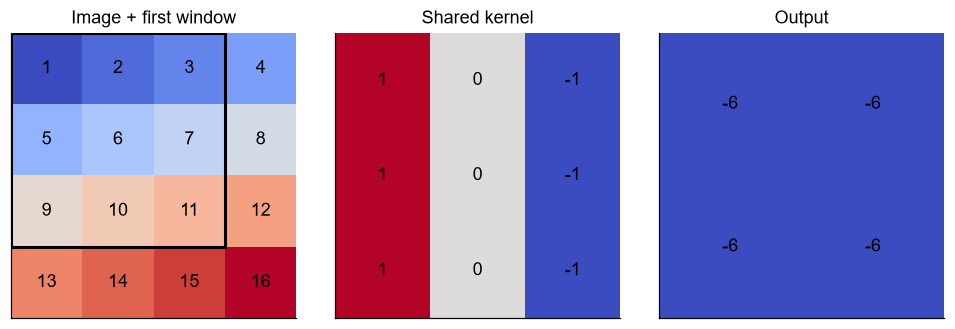

In [7]:
from matplotlib.patches import Rectangle
fig, axes = plt.subplots(1, 3, figsize=(9, 3))
for ax, table, title in zip(axes, [image, kernel, output], ['Image + first window', 'Shared kernel', 'Output']):
    ax.imshow(table, cmap='coolwarm')
    for row, col in np.ndindex(table.shape):
        ax.text(col, row, f'{table[row, col]:g}', ha='center', va='center', fontsize=12)
    ax.set(title=title, xticks=[], yticks=[])
axes[0].add_patch(Rectangle((-.5, -.5), 3, 3, fill=False, edgecolor='black', linewidth=2))
fig.tight_layout(); show(fig)

### 练习 8.2：把2×2核滑遍3×3图

图像是1到9的3×3表，核为全1的2×2表。自己用两个循环返回2×2输出。

In [8]:
ex_t82_result = None

In [9]:
# 填写上一格后，运行检查。
check('窗口滑动', ex_t82_result, [[12., 16.], [24., 28.]])

待填写：窗口滑动


<details>
<summary>提示</summary>

先建立2×2零输出，再逐位置切片 `image[r:r+2,c:c+2]`。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t82_image = np.arange(1, 10).reshape(3, 3)
ex_t82_result = np.zeros((2, 2))
for ex_t82_r in range(2):
    for ex_t82_c in range(2):
        ex_t82_result[ex_t82_r, ex_t82_c] = ex_t82_image[ex_t82_r:ex_t82_r+2, ex_t82_c:ex_t82_c+2].sum()
```

</details>

## 5. stride 与 padding 决定窗口位置


    刚才窗口每次移动一个像素。将 `stride` 改为2，就跳过中间一些位置；
    在边缘补一圈0，即 `padding=1`，窗口便能覆盖到原图边缘附近的新位置。
    设步幅为 s、四边各补 p 个像素，核高为 $k_H$。补零后高度是 $H+2p$，
    一个完整窗口可沿竖直方向移动 $\lfloor(H+2p-k_H)/s\rfloor$ 次，再加初始位置，得到
    $$H_{out}=\left\lfloor\frac{H+2p-k_H}{s}\right\rfloor+1,$$
    宽度用同样方法计算。下格会打印各窗口在补零图中的左上角坐标，
    它们正是下一节切片所需的起点。

In [10]:
padding, stride = 1, 2
padded = np.pad(image, ((padding, padding), (padding, padding)), mode='constant')
height_out = (image.shape[0] + 2 * padding - kernel.shape[0]) // stride + 1
width_out = (image.shape[1] + 2 * padding - kernel.shape[1]) // stride + 1
print('补零后形状:', padded.shape, '输出形状:', (height_out, width_out))
print('各输出窗口的左上角:', [(r * stride, c * stride)
                                for r in range(height_out) for c in range(width_out)])

补零后形状: (6, 6) 输出形状: (2, 2)
各输出窗口的左上角: [(0, 0), (0, 2), (2, 0), (2, 2)]


## 6. 把已经看懂的步骤装成函数


    原来的两个循环可以继续使用，只需把窗口起点改成 `row*stride`、`col*stride`，
    并从补零图中取值。函数里的 `oh`、`ow` 是输出可放的行列数，
    `kh`、`kw` 是每次切片应取的大小。
    末尾用默认步幅1、补零0重算原例，结果应与刚才逐窗口得到的 output 相同。

In [11]:
def conv2d_numpy(array, weight, stride=1, padding=0):
    array = np.asarray(array, dtype=np.float64)
    weight = np.asarray(weight, dtype=np.float64)
    kh, kw = weight.shape
    padded = np.pad(array, ((padding, padding), (padding, padding)))
    oh = (array.shape[0] + 2 * padding - kh) // stride + 1
    ow = (array.shape[1] + 2 * padding - kw) // stride + 1
    result = np.zeros((oh, ow), dtype=np.float64)
    for row in range(oh):
        for col in range(ow):
            start_r, start_c = row * stride, col * stride
            patch = padded[start_r:start_r + kh, start_c:start_c + kw]
            result[row, col] = np.sum(patch * weight)
    return result
check('函数复现手算', conv2d_numpy(image, kernel), output)

通过：函数复现手算


### 练习 8.3：先算输出尺寸

输入高宽均为7，核3×3，padding=1，stride=2。按公式返回 `[Hout,Wout]`。

In [12]:
ex_t83_result = None

In [13]:
# 填写上一格后，运行检查。
check('卷积输出高宽', ex_t83_result, [4, 4])

待填写：卷积输出高宽


<details>
<summary>提示</summary>

整数除法 `//` 完成向下取整。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t83_size = (7 + 2 * 1 - 3) // 2 + 1
ex_t83_result = [ex_t83_size, ex_t83_size]
```

</details>

## 7. 从二维表到 NCHW


    PyTorch 的卷积要同时处理多张图、多种通道，因此输入约定为 `(N,C,H,W)`：
    图像张数、通道数、高、宽。本例只有一张灰度图，
    `[None,None,:,:]` 插入两个长度1的轴，得到 `(1,1,4,4)`，像素值保持原样。

    权重的轴是 `(Cout,Cin,kH,kW)`，这份核为 `(1,1,3,3)`。
    下格将步幅2、补零1传给两种实现，取 PyTorch 输出的 `[0,0]`，
    就能与手写函数的二维输出逐项比较。

In [14]:
torch_image = torch.tensor(image)[None, None, :, :]
torch_kernel = torch.tensor(kernel)[None, None, :, :]
reference = F.conv2d(torch_image, torch_kernel, stride=2, padding=1)
print('输入:', tuple(torch_image.shape), '核:', tuple(torch_kernel.shape),
      '输出:', tuple(reference.shape))
check('NumPy与Conv2d', conv2d_numpy(image, kernel, stride=2, padding=1), reference[0, 0])

输入: (1, 1, 4, 4) 核: (1, 1, 3, 3) 输出: (1, 1, 2, 2)
通过：NumPy与Conv2d


## 8. 多个输入通道汇成一个输出通道


    一张彩色图有多个输入通道。要计算一个输出通道，每个输入通道各有一片核，
    它们的窗口响应相加后，再加这个输出通道的偏置：
    $$Y_{n,o,r,c}=b_o+\sum_{i=1}^{C_{in}}\sum_{u,v}
      K_{o,i,u,v}X_{n,i,rs+u-p,cs+v-p}.$$
    下格的第一个输入通道全是1，第二个全是2，各取2×2窗口、使用全1权重，
    输出就是 $4\times1+4\times2=12$。
    要得到更多输出通道，就学习更多组核。参数总量为
    $C_{out}(C_{in}k_Hk_W+1)$，其中每个输出通道有一个偏置，参数量与图像高宽无关。

In [15]:
channels = torch.stack([torch.ones(3, 3), 2 * torch.ones(3, 3)])[None]
weights = torch.ones(1, 2, 2, 2)
combined = F.conv2d(channels, weights)
print('两个输入通道:', channels.shape, '一个输出通道:', combined.shape)
print('4个1 + 4个2 =', combined[0, 0, 0, 0].item())
layer = nn.Conv2d(2, 3, kernel_size=3, padding=1)
print('可学习参数:', sum(p.numel() for p in layer.parameters()))

两个输入通道: torch.Size([1, 2, 3, 3]) 一个输出通道: torch.Size([1, 1, 2, 2])
4个1 + 4个2 = 12.0
可学习参数: 57


### 练习 8.4：卷积参数量

Conv2d 输入3通道、输出8通道、核3×3、带偏置，返回参数量。图像从32×32变成64×64时参数量是否改变？

In [16]:
ex_t84_result = None

In [17]:
# 填写上一格后，运行检查。
check('共享核参数总量', ex_t84_result, 224)

待填写：共享核参数总量


<details>
<summary>提示</summary>

每个输出通道有3×3×3个核权重和1个偏置。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t84_result = 8 * (3 * 3 * 3 + 1)
```

</details>

## 9. 一个输出的核梯度与输入梯度


    将刚才的局部乘加放回损失中。下面缩小为2×2输入与2×2核，只产生一个输出，
    $q=\sum_{u,v}K_{uv}X_{uv}$，目标为0，$L=\tfrac12q^2$。
    对乘积中的核元素求导留下对应像素，再乘上游导数 q，得到
    $$\frac{\partial L}{\partial K_{uv}}=qX_{uv},\qquad
      \frac{\partial L}{\partial X_{uv}}=qK_{uv}.$$
    对输入求导则留下核元素。下格 q=6，核梯度应为输入表的6倍，
    输入梯度应为核的6倍。这个单窗口例子仍然只是标量乘法的链式法则。

In [18]:
tiny_x = torch.tensor([[[[1., 2.], [3., 4.]]]], requires_grad=True)
tiny_k = torch.tensor([[[[1., 0.], [-1., 2.]]]], requires_grad=True)
tiny_q = F.conv2d(tiny_x, tiny_k)
tiny_loss = 0.5 * tiny_q.square().sum()
tiny_loss.backward()
print('q:', tiny_q.item(), '\n核梯度:\n', tiny_k.grad[0, 0], '\n输入梯度:\n', tiny_x.grad[0, 0])
check('核的局部梯度', tiny_k.grad, tiny_q.detach() * tiny_x.detach())
check('输入的局部梯度', tiny_x.grad, tiny_q.detach() * tiny_k.detach())

q: 6.0 
核梯度:
 tensor([[ 6., 12.],
        [18., 24.]]) 
输入梯度:
 tensor([[ 6.,  0.],
        [-6., 12.]])
通过：核的局部梯度
通过：输入的局部梯度


## 10. 权重共享让核梯度在位置之间相加


    将窗口移遍图像后，同一个 $K_{uv}$ 影响许多输出。
    每个输出都会沿自己的乘法路径给它一份贡献，所有贡献在这个共享权重处相加：
    $$\frac{\partial L}{\partial K_{uv}}
      =\sum_{r,c}\frac{\partial L}{\partial Y_{rc}}X_{r+u,c+v}.$$
    下格取损失为全部输出之和，每个输出的上游梯度都为1。
    核左上角梯度就是四个窗口左上角像素之和：$1+2+4+5=12$。
    同时，图中央像素也被四个窗口使用，它会收到四份输入梯度。
    前一种累加发生在共享参数处，后一种发生在重叠输入处。

In [19]:
overlap_x = torch.arange(1., 10.).reshape(1, 1, 3, 3).requires_grad_()
overlap_k = torch.ones(1, 1, 2, 2, requires_grad=True)
overlap_y = F.conv2d(overlap_x, overlap_k)
overlap_y.sum().backward()
print('共享核的梯度:\n', overlap_k.grad[0, 0])
print('像素收到的贡献次数:\n', overlap_x.grad[0, 0])
check('核左上角累加', overlap_k.grad[0, 0, 0, 0], 1 + 2 + 4 + 5)

共享核的梯度:
 tensor([[12., 16.],
        [24., 28.]])
像素收到的贡献次数:
 tensor([[1., 2., 1.],
        [2., 4., 2.],
        [1., 2., 1.]])
通过：核左上角累加


### 练习 8.5：自己汇总共享权重梯度

图像是1到9的3×3表，2×2核、步幅1，损失是全部输出之和。用窗口累加返回核梯度矩阵。

In [20]:
ex_t85_result = None

In [21]:
# 填写上一格后，运行检查。
check('共享核梯度', ex_t85_result, [[12., 16.], [24., 28.]])

待填写：共享核梯度

<details>
<summary>提示</summary>

每个输出的上游导数为1，把四份2×2窗口相加。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t85_image = np.arange(1., 10.).reshape(3, 3)
ex_t85_result = np.zeros((2, 2))
for ex_t85_r in range(2):
    for ex_t85_c in range(2):
        ex_t85_result += ex_t85_image[ex_t85_r:ex_t85_r+2, ex_t85_c:ex_t85_c+2]
```

</details>

## 11. 画出重叠输入的梯度


    右图的中心是4、角点是1。原因是本例核元素都为1、每个输出梯度也为1，
    所以像素每被一个窗口覆盖一次，就收到一份单位梯度。
    左图则是核各位置收到的像素数值之和，大小为12、16、24、28。
    两张图都来自四份窗口，但它们分别回答了“改核权重”和“改输入像素”怎样影响损失。

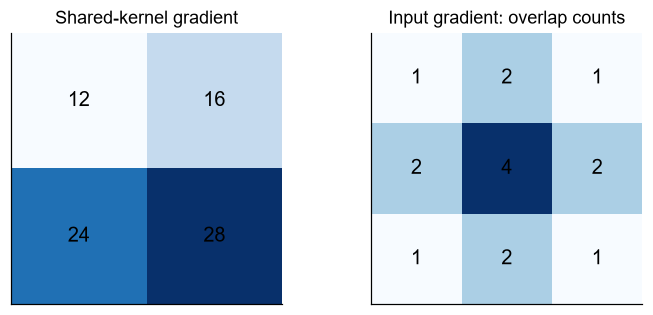

In [22]:
fig, axes = plt.subplots(1, 2, figsize=(6.8, 3))
for ax, values, title in zip(axes, [overlap_k.grad[0, 0], overlap_x.grad[0, 0]],
                             ['Shared-kernel gradient', 'Input gradient: overlap counts']):
    table = values.numpy()
    ax.imshow(table, cmap='Blues')
    for row, col in np.ndindex(table.shape):
        ax.text(col, row, f'{table[row, col]:g}', ha='center', va='center', fontsize=13)
    ax.set(title=title, xticks=[], yticks=[])
fig.tight_layout(); show(fig)

### 练习 8.6：输入中央像素的梯度

3×3输入、全1的2×2核，损失是全部输出之和。建立图并返回输入梯度。

In [23]:
ex_t86_result = None

In [24]:
# 填写上一格后，运行检查。
check('重叠处输入梯度', ex_t86_result, [[1., 2., 1.], [2., 4., 2.], [1., 2., 1.]])

待填写：重叠处输入梯度


<details>
<summary>提示</summary>

输入要是叶节点：先reshape，再 `.requires_grad_()`。

</details>

<details>
<summary>参考答案</summary>

```python
ex_t86_x = torch.zeros(1, 1, 3, 3, requires_grad=True)
F.conv2d(ex_t86_x, torch.ones(1, 1, 2, 2)).sum().backward()
ex_t86_result = ex_t86_x.grad[0, 0].clone()
```

</details>

## 带着问题读原文

[LeCun 等：Gradient-Based Learning Applied to Document Recognition（1998）](https://bottou.org/papers/lecun-98h)

阅读介绍局部感受野和共享权重的部分。假设输入32×32、单通道、6个5×5核、无补零、带偏置：分别计算共享卷积和每个输出位置各用独立权重的参数量。说明共享规则如何限制模型。

**单变量实验：**只把步幅从1改成2，先预测输出形状及中心像素被覆盖次数，再用代码核验。